# FinAssist — Exploratory Data Analysis

## 1. Dataset Overview

This analysis investigates financial data, customer
preferences, trust in digital financial advisors,
and potential data privacy concerns.

Our objective is to identify insights that support
a privacy-first financial advisory platform.

In [2]:
# Import required libraries
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Locate the dataset
possible_paths = [
    Path("datasets/digital_financial_advisor_data.csv"),
    Path("../datasets/digital_financial_advisor_data.csv")
]

data_path = next(
    (path for path in possible_paths if path.exists()),
    None
)

if data_path is None:
    raise FileNotFoundError("Dataset CSV file not found.")

# Load dataset
df = pd.read_csv(data_path)

# Verify dataset
print("Dataset loaded from:", data_path.resolve())
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded from: C:\Users\shaun\OneDrive\Desktop\EPITA\Data Privacy by Design\FinAssist\datasets\digital_financial_advisor_data.csv
Dataset shape: (500, 15)


,Name,Age,Location,Gender,Income,Assets,Debts,Monthly Expenses,Investment Preference,Type of Advice Sought,User Financial Goal,Action Based on Advice,Feedback on Advice,App Usability Feedback,Trust Level with Digital Advisor
0,Michael Cameron,32,"Port Stephenton, Gabon",Male,8576.35,63086.90,3921.93,3046.87,Fixed Deposits,Tax Planning,Tax Savings,Partially Implemented,Very Unsatisfied,Unsatisfied,High
1,Tiffany Silva,53,"Gabrielstad, Bouvet Island (Bouvetoya)",Male,3939.77,22850.65,0.00,953.26,Gold,Retirement Planning,High ROI Investments,Not Implemented,Neutral,Very Unsatisfied,Low
2,Karen Mcintosh,51,"Frederickfort, Cambodia",Female,5751.37,79795.66,0.00,2654.24,Real Estate,Debt Management,Debt Reduction,Partially Implemented,Neutral,Neutral,Low
3,Brian Nelson,39,"Martinezside, Ireland",Female,6966.71,45217.02,0.00,3355.37,Real Estate,Debt Management,High ROI Investments,Partially Implemented,Satisfied,Neutral,Low
4,Julie James,63,"Michaelport, Sierra Leone",Female,5187.90,7766.78,3447.47,4059.88,Mutual Funds,Retirement Planning,High ROI Investments,Implemented,Very Unsatisfied,Very Satisfied,Moderate


In [3]:

# Dataset dimensions
print("Dataset Shape:", df.shape)

# Column names and data types
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Rows:", df.duplicated().sum())


Dataset Shape: (500, 15)
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 15 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Name                              500 non-null    str    
 1   Age                               500 non-null    int64  
 2   Location                          500 non-null    str    
 3   Gender                            500 non-null    str    
 4   Income                            500 non-null    float64
 5   Assets                            500 non-null    float64
 6   Debts                             500 non-null    float64
 7   Monthly Expenses                  500 non-null    float64
 8   Investment Preference             500 non-null    str    
 9   Type of Advice Sought             500 non-null    str    
 10  User Financial Goal               500 non-null    str    
 11  Action Based on Advice            500 non-null    str    

In [4]:

# Summary statistics for numerical columns
df.describe().round(2)


,Age,Income,Assets,Debts,Monthly Expenses
count,500.00,500.00,500.00,500.00,500.00
mean,43.03,6026.41,50692.15,1232.97,2866.35
std,15.33,2307.38,27372.25,1641.73,1306.70
min,18.00,2000.09,5609.11,0.00,507.64
25%,30.00,4001.92,26371.52,0.00,1846.91
50%,41.00,6043.26,49509.26,0.00,2866.36
75%,56.00,7945.04,74434.85,2445.51,4044.53
max,70.00,9970.47,99921.61,4983.95,4994.32


## 2. Customer Trust Analysis

We investigate customers' reported trust levels
in digital financial advisors.

In [5]:

trust_counts = (
    df["Trust Level with Digital Advisor"]
    .value_counts()
    .reindex(["Low", "Moderate", "High"])
)

trust_percent = (
    df["Trust Level with Digital Advisor"]
    .value_counts(normalize=True)
    .reindex(["Low", "Moderate", "High"]) * 100
)

print("Trust Counts:")
print(trust_counts)

print("\nTrust Percentages:")
print(trust_percent.round(2))


Trust Counts:
Trust Level with Digital Advisor
Low         184
Moderate    153
High        163
Name: count, dtype: int64

Trust Percentages:
Trust Level with Digital Advisor
Low         36.8
Moderate    30.6
High        32.6
Name: proportion, dtype: float64


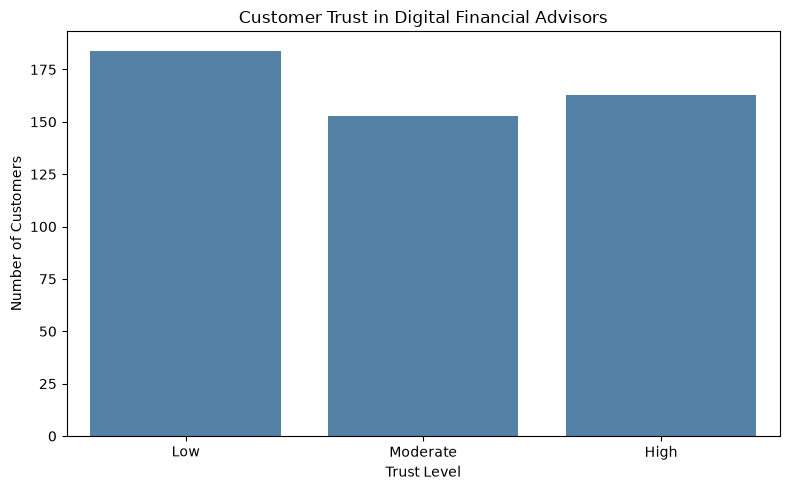

In [6]:

plt.figure(figsize=(8, 5))

sns.barplot(
    x=trust_counts.index,
    y=trust_counts.values,
    color="steelblue"
)

plt.title("Customer Trust in Digital Financial Advisors")
plt.xlabel("Trust Level")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()


### Finding 1: Customer Trust

The dataset contains 500 customer records.

Our analysis shows that:
- 36.8% of customers report low trust.
- 30.6% report moderate trust.
- 32.6% report high trust.

Low trust is the most frequently reported level.

This finding suggests that building customer trust
should be an important consideration for FinAssist.

However, the dataset does not establish why
customers have low trust. Additional customer
research is needed to investigate privacy concerns.

## 3. Customer Behavior Analysis

### Relationship Between Trust and Financial Advice

Objective:
Investigate whether customers with different trust
levels behave differently after receiving financial advice.

In [7]:

# Customer actions
action_counts = df["Action Based on Advice"].value_counts()

print("Customer Actions:")
print(action_counts)

# Compare customer trust and actions
trust_action = pd.crosstab(
    df["Trust Level with Digital Advisor"],
    df["Action Based on Advice"]
)

display(trust_action)


Customer Actions:
Action Based on Advice
Implemented                     136
Seeking Further Consultation    133
Partially Implemented           130
Not Implemented                 101
Name: count, dtype: int64


Action Based on Advice,Implemented,Not Implemented,Partially Implemented,Seeking Further Consultation
Trust Level with Digital Advisor,,,,
High,46,33,43,41
Low,49,38,50,47
Moderate,41,30,37,45


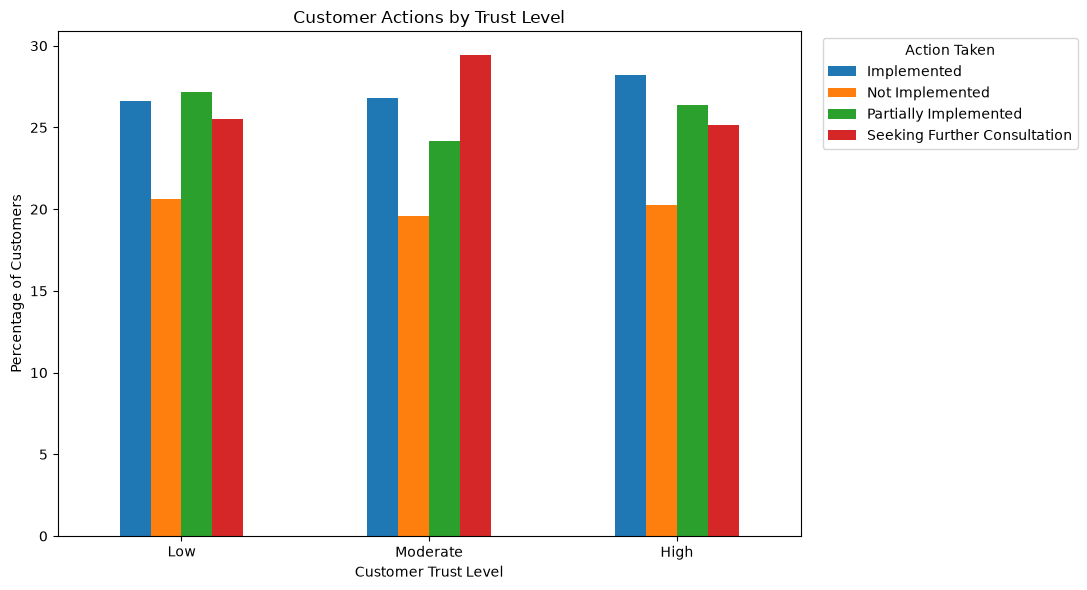

In [8]:

# Convert counts to percentages within each trust group
trust_action_percent = pd.crosstab(
    df["Trust Level with Digital Advisor"],
    df["Action Based on Advice"],
    normalize="index"
) * 100

# Set trust level order
trust_action_percent = trust_action_percent.reindex(
    ["Low", "Moderate", "High"]
)

# Create chart
ax = trust_action_percent.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Customer Actions by Trust Level")
plt.xlabel("Customer Trust Level")
plt.ylabel("Percentage of Customers")
plt.xticks(rotation=0)
plt.legend(title="Action Taken", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()


### Finding 2: Customer Trust and Financial Behavior

The analysis examines the relationship between
trust levels and actions taken after financial advice.

Results:
- 136 customers implemented the advice.
- 133 sought further consultation.
- 130 partially implemented the advice.
- 101 did not implement the advice.

The implementation rate is similar across low,
moderate, and high trust groups.

These findings indicate that reported trust alone
does not clearly explain customer behavior in this dataset.

Further research is needed to understand whether
privacy, usability, advice quality, or other factors
influence financial decision-making.

## 4. Financial Data Sensitivity Analysis

### Objective
Identify and classify sensitive personal and financial
information contained in the FinAssist dataset.

The analysis aims to:
- Identify personally identifiable information.
- Classify financial data by sensitivity.
- Evaluate potential privacy risks.
- Recommend appropriate security measures.

In [9]:

# Classify all 15 dataset columns by privacy sensitivity

risk_data = [
    ("Name", "High", "Direct identification",
     "Remove from analytical outputs"),

    ("Age", "Medium", "Re-identification when combined",
     "Use age groups"),

    ("Location", "High", "Location-based identification",
     "Use broader geographic regions"),

    ("Gender", "Medium", "Personal profiling",
     "Restrict unnecessary processing"),

    ("Income", "High", "Exposure of earnings",
     "Restrict access and encrypt"),

    ("Assets", "High", "Exposure of financial wealth",
     "Restrict access and encrypt"),

    ("Debts", "High", "Exposure of financial liabilities",
     "Restrict access and encrypt"),

    ("Monthly Expenses", "High", "Exposure of spending patterns",
     "Restrict access and encrypt"),

    ("Investment Preference", "Medium-High",
     "Financial profiling",
     "Limit collection and access"),

    ("Type of Advice Sought", "Medium-High",
     "Disclosure of financial needs",
     "Limit access"),

    ("User Financial Goal", "Medium-High",
     "Exposure of financial plans",
     "Limit collection and access"),

    ("Action Based on Advice", "Medium",
     "Behavioral profiling",
     "Use aggregated reporting"),

    ("Feedback on Advice", "Medium",
     "Disclosure of customer opinions",
     "Remove direct identifiers"),

    ("App Usability Feedback", "Medium",
     "Disclosure of customer opinions",
     "Remove direct identifiers"),

    ("Trust Level with Digital Advisor", "Medium",
     "Behavioral profiling",
     "Use aggregated reporting")
]

risk_df = pd.DataFrame(
    risk_data,
    columns=[
        "Data Column",
        "Sensitivity",
        "Potential Risk",
        "Recommended Protection"
    ]
)

display(risk_df)


,Data Column,Sensitivity,Potential Risk,Recommended Protection
0,Name,High,Direct identification,Remove from analytical outputs
1,Age,Medium,Re-identification when combined,Use age groups
2,Location,High,Location-based identification,Use broader geographic regions
3,Gender,Medium,Personal profiling,Restrict unnecessary processing
4,Income,High,Exposure of earnings,Restrict access and encrypt
5,Assets,High,Exposure of financial wealth,Restrict access and encrypt
6,Debts,High,Exposure of financial liabilities,Restrict access and encrypt
7,Monthly Expenses,High,Exposure of spending patterns,Restrict access and encrypt
8,Investment Preference,Medium-High,Financial profiling,Limit collection and access
9,Type of Advice Sought,Medium-High,Disclosure of financial needs,Limit access


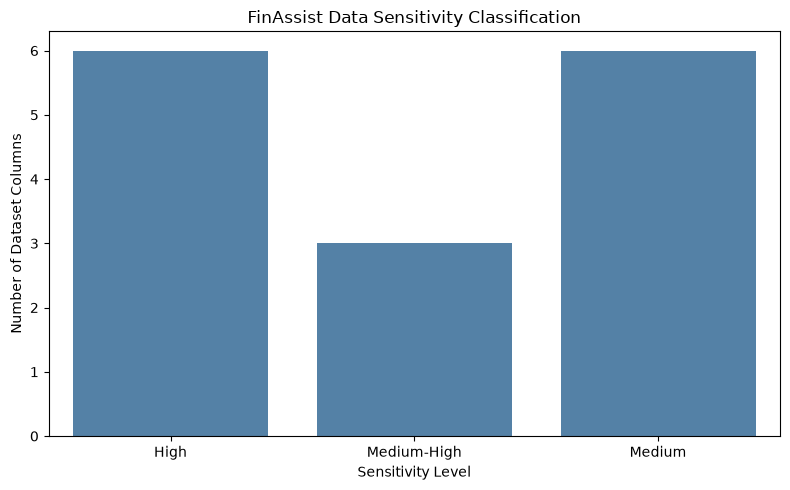

Sensitivity
High           6
Medium-High    3
Medium         6
Name: count, dtype: int64


In [10]:

sensitivity_counts = (
    risk_df["Sensitivity"]
    .value_counts()
    .reindex(["High", "Medium-High", "Medium"])
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=sensitivity_counts.index,
    y=sensitivity_counts.values,
    color="steelblue"
)

plt.title("FinAssist Data Sensitivity Classification")
plt.xlabel("Sensitivity Level")
plt.ylabel("Number of Dataset Columns")

plt.tight_layout()
plt.show()

print(sensitivity_counts)


In [11]:

# Create age groups instead of using exact ages
df["Age Group"] = pd.cut(
    df["Age"],
    bins=[17, 29, 44, 59, float("inf")],
    labels=["18-29", "30-44", "45-59", "60+"]
)

# Use only the data needed for this analysis
analysis_data = df[
    ["Age Group", "Trust Level with Digital Advisor"]
].copy()

# Aggregate customer counts
summary = pd.crosstab(
    analysis_data["Age Group"],
    analysis_data["Trust Level with Digital Advisor"]
)

display(summary)


Trust Level with Digital Advisor,High,Low,Moderate
Age Group,,,
18-29,48,42,29
30-44,43,63,51
45-59,42,46,36
60+,30,33,37


In [12]:

risk_df.to_csv(
    "privacy_risk_assessment.csv",
    index=False
)

print("Privacy risk assessment saved successfully.")


Privacy risk assessment saved successfully.


### Finding 3: Financial Data Sensitivity

The FinAssist dataset contains 15 columns with
different privacy and security implications.

Our preliminary assessment classified:
- 6 columns as High sensitivity.
- 3 columns as Medium-High sensitivity.
- 6 columns as Medium sensitivity.

Names and financial records present significant
privacy risks if accessed or disclosed without
authorization.

Combining financial information with identifying
attributes may increase the risk of individual
profiling and re-identification.

Recommended protections include data minimization,
access controls, encryption, pseudonymization,
and aggregated reporting.

These measures will form part of the proposed
FinAssist privacy-first strategy.

# 5. Cybersecurity Threat and Risk Assessment

## Objective
Identify potential cybersecurity threats affecting FinAssist,
evaluate their likelihood and impact, and recommend
appropriate security controls.

## Methodology
We use a qualitative risk assessment with:
- Likelihood scored from 1 to 5
- Impact scored from 1 to 5
- Risk Score = Likelihood × Impact

Risk levels:
- Low: 1–8
- Medium: 9–14
- High: 15–25

The scores are illustrative assessments of a proposed
system, not measured vulnerabilities in the dataset.

In [13]:

# Potential cybersecurity threats for FinAssist

threats = [
    {
        "Threat": "Unauthorized Access",
        "Likelihood": 4,
        "Impact": 5,
        "Protection": "MFA and access control"
    },
    {
        "Threat": "Data Leakage",
        "Likelihood": 3,
        "Impact": 5,
        "Protection": "Encryption and secure configuration"
    },
    {
        "Threat": "Insider Threats",
        "Likelihood": 3,
        "Impact": 4,
        "Protection": "Least privilege and audit logs"
    },
    {
        "Threat": "Insecure Transmission",
        "Likelihood": 3,
        "Impact": 5,
        "Protection": "TLS and secure communication"
    },
    {
        "Threat": "Third-Party Exposure",
        "Likelihood": 3,
        "Impact": 4,
        "Protection": "Vendor assessment and data minimization"
    },
    {
        "Threat": "Excessive Data Collection",
        "Likelihood": 4,
        "Impact": 4,
        "Protection": "Data minimization and retention limits"
    }
]

threat_df = pd.DataFrame(threats)

# Calculate risk scores
threat_df["Risk Score"] = (
    threat_df["Likelihood"] * threat_df["Impact"]
)

# Assign risk levels
def risk_level(score):
    if score >= 15:
        return "High"
    elif score >= 9:
        return "Medium"
    return "Low"

threat_df["Risk Level"] = (
    threat_df["Risk Score"].apply(risk_level)
)

threat_df = threat_df.sort_values(
    "Risk Score", ascending=False
)

display(threat_df)


,Threat,Likelihood,Impact,Protection,Risk Score,Risk Level
0,Unauthorized Access,4,5,MFA and access control,20,High
5,Excessive Data Collection,4,4,Data minimization and retention limits,16,High
1,Data Leakage,3,5,Encryption and secure configuration,15,High
3,Insecure Transmission,3,5,TLS and secure communication,15,High
2,Insider Threats,3,4,Least privilege and audit logs,12,Medium
4,Third-Party Exposure,3,4,Vendor assessment and data minimization,12,Medium


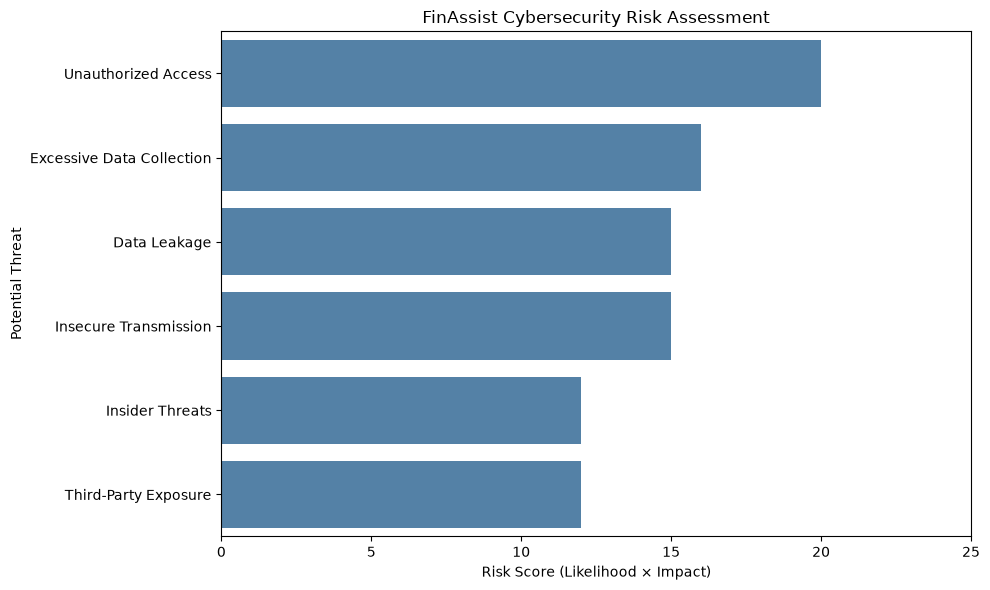

In [14]:

plt.figure(figsize=(10, 6))

sns.barplot(
    data=threat_df,
    x="Risk Score",
    y="Threat",
    color="steelblue"
)

plt.title("FinAssist Cybersecurity Risk Assessment")
plt.xlabel("Risk Score (Likelihood × Impact)")
plt.ylabel("Potential Threat")
plt.xlim(0, 25)

plt.tight_layout()
plt.show()


In [15]:

# Export cybersecurity risk assessment

threat_df.to_csv(
    "cybersecurity_risk_assessment.csv",
    index=False
)

print("Cybersecurity risk assessment saved!")


Cybersecurity risk assessment saved!


In [16]:
# Verify exported cybersecurity risk assessment

from pathlib import Path
import pandas as pd

print("Saved in:", Path("cybersecurity_risk_assessment.csv").resolve())

risk_file = Path("cybersecurity_risk_assessment.csv")

if risk_file.exists():
    exported_df = pd.read_csv(risk_file)

    print("File exists:", risk_file.resolve())
    print("Number of threats:", len(exported_df))

    display(exported_df)
else:
    print("Export file not found!")

Saved in: C:\Users\shaun\OneDrive\Desktop\EPITA\Data Privacy by Design\FinAssist\analysis\cybersecurity_risk_assessment.csv
File exists: C:\Users\shaun\OneDrive\Desktop\EPITA\Data Privacy by Design\FinAssist\analysis\cybersecurity_risk_assessment.csv
Number of threats: 6


,Threat,Likelihood,Impact,Protection,Risk Score,Risk Level
0,Unauthorized Access,4,5,MFA and access control,20,High
1,Excessive Data Collection,4,4,Data minimization and retention limits,16,High
2,Data Leakage,3,5,Encryption and secure configuration,15,High
3,Insecure Transmission,3,5,TLS and secure communication,15,High
4,Insider Threats,3,4,Least privilege and audit logs,12,Medium
5,Third-Party Exposure,3,4,Vendor assessment and data minimization,12,Medium



# 6. Regulatory Compliance Assessment

## 6.1 General Data Protection Regulation (GDPR)

FinAssist is designed for users who may reside in the European Union. Therefore, the platform must consider the GDPR when processing personal data within its scope.

The GDPR establishes requirements for collecting, using, storing, securing, and sharing personal information.

The following assessment maps the GDPR's core principles to practical measures that FinAssist should implement.


In [17]:
# Create GDPR compliance assessment

gdpr_data = [
    {
        "GDPR Principle": "Lawfulness, Fairness and Transparency",
        "Requirement": "Process personal data lawfully and explain how it is used.",
        "FinAssist Implementation": "Provide a clear privacy notice and identify an appropriate legal basis for each processing purpose."
    },
    {
        "GDPR Principle": "Purpose Limitation",
        "Requirement": "Collect data for specific, explicit and legitimate purposes.",
        "FinAssist Implementation": "Use financial information only for disclosed purposes, such as financial analysis and personalised advice."
    },
    {
        "GDPR Principle": "Data Minimisation",
        "Requirement": "Collect only data necessary for the intended purpose.",
        "FinAssist Implementation": "Avoid collecting unnecessary identity and financial details."
    },
    {
        "GDPR Principle": "Accuracy",
        "Requirement": "Keep personal data accurate and up to date.",
        "FinAssist Implementation": "Allow users to review and correct their financial information."
    },
    {
        "GDPR Principle": "Storage Limitation",
        "Requirement": "Keep personal data only for as long as necessary.",
        "FinAssist Implementation": "Establish retention periods and securely delete data when it is no longer required."
    },
    {
        "GDPR Principle": "Integrity and Confidentiality",
        "Requirement": "Protect personal data against unauthorised access, loss and disclosure.",
        "FinAssist Implementation": "Use encryption, multi-factor authentication, access controls and secure backups."
    },
    {
        "GDPR Principle": "Accountability",
        "Requirement": "Demonstrate compliance with data protection principles.",
        "FinAssist Implementation": "Maintain processing records, document security controls and review compliance regularly."
    }
]

gdpr_df = pd.DataFrame(gdpr_data)

display(gdpr_df)

,GDPR Principle,Requirement,FinAssist Implementation
0,"Lawfulness, Fairness and Transparency",Process personal data lawfully and explain how...,Provide a clear privacy notice and identify an...
1,Purpose Limitation,"Collect data for specific, explicit and legiti...",Use financial information only for disclosed p...
2,Data Minimisation,Collect only data necessary for the intended p...,Avoid collecting unnecessary identity and fina...
3,Accuracy,Keep personal data accurate and up to date.,Allow users to review and correct their financ...
4,Storage Limitation,Keep personal data only for as long as necessary.,Establish retention periods and securely delet...
5,Integrity and Confidentiality,Protect personal data against unauthorised acc...,"Use encryption, multi-factor authentication, a..."
6,Accountability,Demonstrate compliance with data protection pr...,"Maintain processing records, document security..."


In [18]:
# Export GDPR compliance assessment

gdpr_file = Path("gdpr_compliance_assessment.csv")

gdpr_df.to_csv(gdpr_file, index=False)

print("GDPR assessment saved to:", gdpr_file.resolve())

GDPR assessment saved to: C:\Users\shaun\OneDrive\Desktop\EPITA\Data Privacy by Design\FinAssist\analysis\gdpr_compliance_assessment.csv


## 6.2 Gramm-Leach-Bliley Act (GLBA)

The Gramm-Leach-Bliley Act (GLBA) is a United States
federal law introduced in 1999 to protect consumers'
personal financial information.

As FinAssist provides personalised financial advice,
GLBA requirements may become applicable if the platform
operates within the relevant United States regulatory scope.

The GLBA addresses three major areas:

- Financial Privacy Rule: Transparency and restrictions
  on sharing personal financial information.
- Safeguards Rule: Security measures to protect customer
  information.
- Pretexting Protection: Prevention of fraudulent access
  to personal financial information.

The following assessment maps GLBA requirements to
proposed privacy and security measures for FinAssist.

Reference:
https://www.ftc.gov/business-guidance/privacy-security/gramm-leach-bliley-act

In [19]:
# Create GLBA compliance assessment

glba_data = [
    {
        "GLBA Requirement": "Financial Privacy Notice",
        "Requirement": "Inform customers about financial data collection and sharing practices.",
        "FinAssist Implementation": "Provide a clear privacy notice explaining how financial information is collected, processed and shared."
    },
    {
        "GLBA Requirement": "Opt-Out Rights",
        "Requirement": "Allow consumers to opt out of certain information sharing with nonaffiliated third parties.",
        "FinAssist Implementation": "Provide privacy settings to control applicable third-party data sharing."
    },
    {
        "GLBA Requirement": "Information Security Programme",
        "Requirement": "Establish and maintain safeguards to protect customer information.",
        "FinAssist Implementation": "Implement encryption, access controls, secure authentication and documented security policies."
    },
    {
        "GLBA Requirement": "Risk Assessment",
        "Requirement": "Identify and assess risks to customer information.",
        "FinAssist Implementation": "Perform regular cybersecurity and privacy risk assessments."
    },
    {
        "GLBA Requirement": "Third-Party Security",
        "Requirement": "Ensure service providers adequately protect customer information.",
        "FinAssist Implementation": "Evaluate third-party services and restrict access to necessary financial data."
    },
    {
        "GLBA Requirement": "Pretexting Protection",
        "Requirement": "Prevent fraudulent access to customer financial information.",
        "FinAssist Implementation": "Use multi-factor authentication, identity verification and suspicious activity monitoring."
    },
    {
        "GLBA Requirement": "Security Monitoring and Testing",
        "Requirement": "Monitor and evaluate the effectiveness of security safeguards.",
        "FinAssist Implementation": "Perform security testing, maintain audit logs and regularly review access controls."
    }
]

glba_df = pd.DataFrame(glba_data)

display(glba_df)

,GLBA Requirement,Requirement,FinAssist Implementation
0,Financial Privacy Notice,Inform customers about financial data collecti...,Provide a clear privacy notice explaining how ...
1,Opt-Out Rights,Allow consumers to opt out of certain informat...,Provide privacy settings to control applicable...
2,Information Security Programme,Establish and maintain safeguards to protect c...,"Implement encryption, access controls, secure ..."
3,Risk Assessment,Identify and assess risks to customer informat...,Perform regular cybersecurity and privacy risk...
4,Third-Party Security,Ensure service providers adequately protect cu...,Evaluate third-party services and restrict acc...
5,Pretexting Protection,Prevent fraudulent access to customer financia...,"Use multi-factor authentication, identity veri..."
6,Security Monitoring and Testing,Monitor and evaluate the effectiveness of secu...,"Perform security testing, maintain audit logs ..."


In [20]:
# Export GLBA compliance assessment

glba_file = Path("glba_compliance_assessment.csv")

glba_df.to_csv(glba_file, index=False)

print("GLBA assessment saved to:", glba_file.resolve())

GLBA assessment saved to: C:\Users\shaun\OneDrive\Desktop\EPITA\Data Privacy by Design\FinAssist\analysis\glba_compliance_assessment.csv


### GLBA Assessment Findings

The assessment identifies several privacy and security
requirements relevant to the proposed FinAssist platform.

- Financial information should be protected through
  encryption and restricted access.
- Customers should understand how their financial
  information is collected and shared.
- Third-party access should be carefully controlled.
- Regular security assessments should be conducted.
- Strong authentication should help prevent fraudulent
  access to financial information.

The proposed measures support both GDPR and GLBA
privacy objectives.

However, actual regulatory compliance depends on the
platform's jurisdiction, business activities and verified
implementation of the required controls.

# 7. Competitor Privacy Strategy Analysis

To develop FinAssist as a privacy-first financial advisory
platform, it is important to examine the privacy and
security strategies of existing competitors.

The selected competitors are:

- Betterment
- Wealthfront
- Empower

The comparison focuses on data protection, authentication,
data sharing, user privacy controls and potential
privacy risks.

The objective is to identify industry best practices
and opportunities for FinAssist to improve customer
privacy and trust.

The assessment is based on publicly available privacy
policies and security documentation, rather than
independent security audits.

In [21]:
# Create competitor privacy strategy assessment

competitor_data = [
    {
        "Competitor": "Betterment",
        "Primary Service": "Automated investment advisory",
        "Data Protection": "Encryption in transit and at rest",
        "Authentication": "Two-factor authentication",
        "Privacy Strength": "Restricted employee access to personal information",
        "Potential Limitation": "Certain information is retained after account deletion",
        "FinAssist Strategy": "Implement encryption, restricted access and transparent retention policies"
    },
    {
        "Competitor": "Wealthfront",
        "Primary Service": "Automated investing and financial planning",
        "Data Protection": "Fraud monitoring and app-specific passwords",
        "Authentication": "Mandatory two-factor authentication",
        "Privacy Strength": "Additional protection against unauthorised account access",
        "Potential Limitation": "External application connections introduce additional privacy risks",
        "FinAssist Strategy": "Implement mandatory MFA and restrict third-party integrations"
    },
    {
        "Competitor": "Empower",
        "Primary Service": "Personal finance and wealth management",
        "Data Protection": "AES-256 encryption and continuous monitoring",
        "Authentication": "Multi-factor authentication",
        "Privacy Strength": "Multilayered security and device access management",
        "Potential Limitation": "Financial account aggregation increases data exposure",
        "FinAssist Strategy": "Apply data minimisation and avoid unnecessary financial account connections"
    }
]

competitor_df = pd.DataFrame(competitor_data)

display(competitor_df)

,Competitor,Primary Service,Data Protection,Authentication,Privacy Strength,Potential Limitation,FinAssist Strategy
0,Betterment,Automated investment advisory,Encryption in transit and at rest,Two-factor authentication,Restricted employee access to personal informa...,Certain information is retained after account ...,"Implement encryption, restricted access and tr..."
1,Wealthfront,Automated investing and financial planning,Fraud monitoring and app-specific passwords,Mandatory two-factor authentication,Additional protection against unauthorised acc...,External application connections introduce add...,Implement mandatory MFA and restrict third-par...
2,Empower,Personal finance and wealth management,AES-256 encryption and continuous monitoring,Multi-factor authentication,Multilayered security and device access manage...,Financial account aggregation increases data e...,Apply data minimisation and avoid unnecessary ...


In [22]:
# Compare documented privacy and security mechanisms

privacy_features = {
    "Privacy Feature": [
        "Encryption in Transit",
        "Encryption at Rest",
        "Multi-Factor Authentication",
        "Security Monitoring",
        "Third-Party Access Protection",
        "Data Minimisation",
        "Data Deletion Controls",
        "Pseudonymisation"
    ],
    "Betterment": [
        "Documented",
        "Documented",
        "Documented",
        "Documented",
        "Documented",
        "Not Assessed",
        "Documented",
        "Not Assessed"
    ],
    "Wealthfront": [
        "Not Assessed",
        "Not Assessed",
        "Documented",
        "Documented",
        "Documented",
        "Not Assessed",
        "Not Assessed",
        "Not Assessed"
    ],
    "Empower": [
        "Documented",
        "Documented",
        "Documented",
        "Documented",
        "Not Assessed",
        "Not Assessed",
        "Not Assessed",
        "Not Assessed"
    ],
    "FinAssist": ["Planned"] * 8
}

privacy_features_df = pd.DataFrame(privacy_features)

display(privacy_features_df)

,Privacy Feature,Betterment,Wealthfront,Empower,FinAssist
0,Encryption in Transit,Documented,Not Assessed,Documented,Planned
1,Encryption at Rest,Documented,Not Assessed,Documented,Planned
2,Multi-Factor Authentication,Documented,Documented,Documented,Planned
3,Security Monitoring,Documented,Documented,Documented,Planned
4,Third-Party Access Protection,Documented,Documented,Not Assessed,Planned
5,Data Minimisation,Not Assessed,Not Assessed,Not Assessed,Planned
6,Data Deletion Controls,Documented,Not Assessed,Not Assessed,Planned
7,Pseudonymisation,Not Assessed,Not Assessed,Not Assessed,Planned


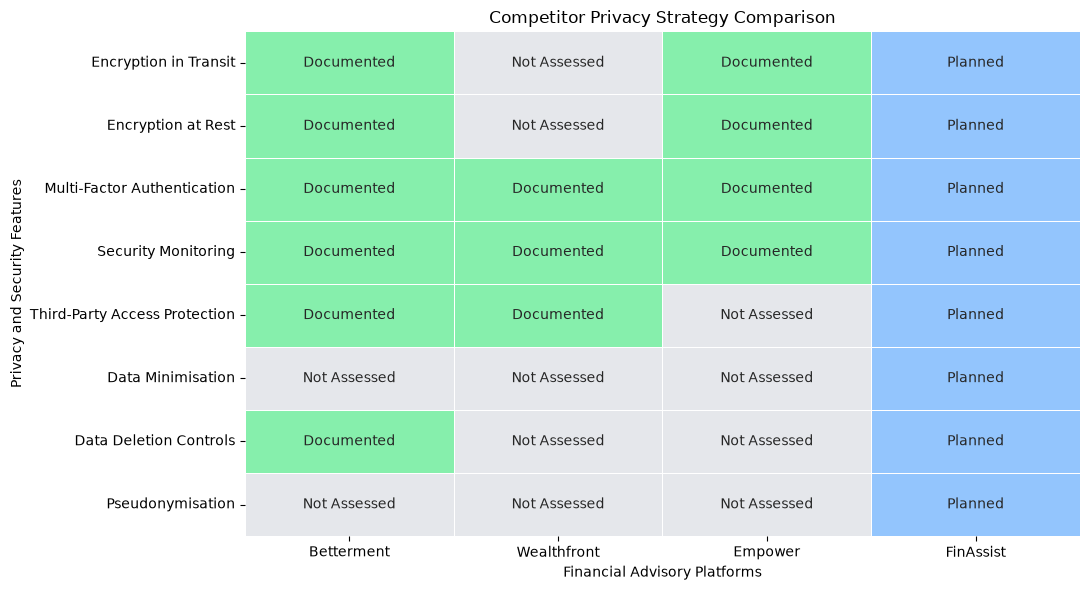

In [23]:
# Visualise the documented privacy mechanisms

import matplotlib.pyplot as plt
import seaborn as sns

platforms = ["Betterment", "Wealthfront", "Empower", "FinAssist"]

comparison_df = privacy_features_df.set_index(
    "Privacy Feature"
)

status_mapping = {
    "Not Assessed": 0,
    "Planned": 1,
    "Documented": 2
}

heatmap_data = comparison_df[platforms].replace(
    status_mapping
).astype(int)

plt.figure(figsize=(11, 6))

sns.heatmap(
    heatmap_data,
    annot=comparison_df[platforms],
    fmt="",
    cmap=["#e5e7eb", "#93c5fd", "#86efac"],
    vmin=0,
    vmax=2,
    linewidths=0.5,
    cbar=False
)

plt.title("Competitor Privacy Strategy Comparison")
plt.xlabel("Financial Advisory Platforms")
plt.ylabel("Privacy and Security Features")
plt.tight_layout()
plt.show()

In [24]:
# Export competitor privacy assessments

competitor_file = Path("competitor_privacy_analysis.csv")

competitor_df.to_csv(competitor_file, index=False)

features_file = Path("competitor_privacy_features.csv")

privacy_features_df.to_csv(features_file, index=False)

print("Competitor assessment saved to:",
      competitor_file.resolve())

print("Privacy features saved to:",
      features_file.resolve())

Competitor assessment saved to: C:\Users\shaun\OneDrive\Desktop\EPITA\Data Privacy by Design\FinAssist\analysis\competitor_privacy_analysis.csv
Privacy features saved to: C:\Users\shaun\OneDrive\Desktop\EPITA\Data Privacy by Design\FinAssist\analysis\competitor_privacy_features.csv


### 7.1 Competitor Analysis Findings

The competitor analysis identifies encryption,
multi-factor authentication and security monitoring
as important practices for protecting financial data.

FinAssist should adopt these practices while placing
additional emphasis on privacy by design.

The proposed strategies for FinAssist include:

- Data minimisation during information collection.
- Encryption of sensitive financial information.
- Multi-factor authentication.
- Pseudonymisation before analytical processing.
- Transparency regarding AI-based data processing.
- User-controlled data access and deletion.
- Restrictions on unnecessary third-party data sharing.

These measures aim to reduce privacy risks and improve
customer trust.

### 7.2 Assessment Limitations

The comparison is based on publicly available
documentation. It does not verify the internal
implementation or effectiveness of competitor controls.

FinAssist's proposed features must be implemented and
tested before their effectiveness can be established.

### 7.3 References

Betterment:
- https://www.betterment.com/legal/privacy-policy
- https://www.betterment.com/legal/security

Wealthfront:
- https://support.wealthfront.com/hc/en-us/articles/211004563-Two-Factor-Authentication
- https://support.wealthfront.com/hc/en-us/articles/360038905371-Security-for-checking-features

Empower:
- https://www.empower.com/tools
- https://support-personalwealth.empower.com/hc/en-us/articles/201169540-Multiple-Layers-of-Security

Accessed: 28 November 2026.